<a href="https://colab.research.google.com/github/cmd0850/Chislovy_metodi/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D0%9B%D0%A012_RNN_LSTM_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** ____________________________________  
**Група:** _____________________________________________  
**Дата:** ______________________________________________

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts='''Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..'''

print(texts)

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
texts = texts.replace('\ufeff', '')

maxWordsCount = 1000

tokenizer = Tokenizer(
    num_words=maxWordsCount,
    filters='!"#$%&()*+,-–—./:;<=>?@[\\]^_`{|}~\t\n«»„“”…',
    lower=True,
    split=' ',
    char_level=False
)

tokenizer.fit_on_texts([texts])

print("Унікальних слів:", len(tokenizer.word_index))
print(list(tokenizer.word_index.items())[:10])

Унікальних слів: 35
[('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
res = np.array(tokenizer.texts_to_sequences([texts])[0])

inp_words = 3
n = len(res) - inp_words

X = np.array([res[i:i + inp_words] for i in range(n)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)

print("X:", X.shape)
print("Y:", Y.shape)

print("Перший приклад:", X[0])
print("Слова:", [tokenizer.index_word[i] for i in X[0]])
print("Цільове слово:", tokenizer.index_word[np.argmax(Y[0])])

X: (49, 3)
Y: (49, 1000)
Перший приклад: [7 8 7]
Слова: ['думи', 'мої', 'думи']
Цільове слово: мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [5]:
model = Sequential([
    Embedding(maxWordsCount, 300, input_length=inp_words),
    SimpleRNN(128, activation='tanh', return_sequences=True),
    LSTM(128, activation='tanh'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(maxWordsCount, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [7]:
history = model.fit(X, Y, batch_size=32, epochs=50)

print("Loss:", history.history['loss'][-1])
print("Accuracy:", history.history['accuracy'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.0000e+00 - loss: 6.9081
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1837 - loss: 6.8943
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3265 - loss: 6.8797
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3265 - loss: 6.8595
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3061 - loss: 6.8290
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2449 - loss: 6.7829
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1837 - loss: 6.6959
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1633 - loss: 6.5390
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1633 - loss: 6.2472
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1020 - loss: 5.7022
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1020 - loss: 4.8887
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1020 - loss: 4.06

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

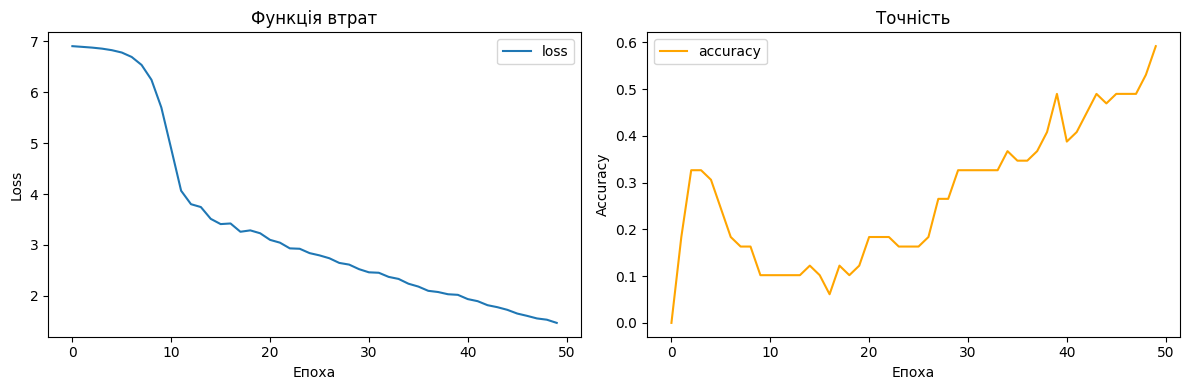

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='loss')
axes[0].set_title('Функція втрат')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='accuracy', color='orange')
axes[1].set_title('Точність')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [9]:
def buildPhrase(texts, str_len=20):
    data = tokenizer.texts_to_sequences([texts])[0]

    if len(data) < inp_words:
        raise ValueError(
            f"Потрібно щонайменше {inp_words} слова, відомих токенізатору "
            f"(знайдено {len(data)})."
        )

    res = texts

    for _ in range(str_len):
        x = np.array(data[-inp_words:]).reshape(1, inp_words)

        pred = model.predict(x, verbose=0)
        index = np.argmax(pred)

        data.append(index)
        res += " " + tokenizer.index_word[index]

    return res


print(buildPhrase("Думи мої думи", str_len=20))


Думи мої думи лихо лихо лихо на на на поливали поливали рядами не не папері в в чом як чом не не не


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [10]:
%pip install keras-tuner

import keras_tuner as kt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [11]:
def build_model(hp):
    embedding_dim = hp.Int('embedding_dim', min_value=128, max_value=512, step=64)
    rnn_units = hp.Int('rnn_units', min_value=64, max_value=256, step=64)
    lstm_units = hp.Int('lstm_units', min_value=64, max_value=256, step=64)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    dense_units = hp.Int('dense_units', min_value=64, max_value=256, step=64)
    optimizer = hp.Choice('optimizer', ['adam', 'rmsprop'])

    model = Sequential([
        Embedding(maxWordsCount, embedding_dim, input_length=inp_words),
        SimpleRNN(rnn_units, activation='tanh', return_sequences=True),
        LSTM(lstm_units, activation='tanh'),
        Dropout(dropout_rate),
        Dense(dense_units, activation='relu'),
        Dense(maxWordsCount, activation='softmax')
    ])

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [12]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction'
)

tuner.search(X, Y, epochs=10, batch_size=32)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

for name in ['embedding_dim', 'rnn_units', 'lstm_units',
             'dropout_rate', 'dense_units', 'optimizer']:
    print(f"{name}: {best_hp.get(name)}")

Trial 10 Complete [00h 00m 05s]
accuracy: 0.18367347121238708

Best accuracy So Far: 0.5102040767669678
Total elapsed time: 00h 00m 52s
embedding_dim: 512
rnn_units: 128
lstm_units: 192
dropout_rate: 0.1
dense_units: 128
optimizer: adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [13]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

best_model = tuner.hypermodel.build(best_hps)

best_history = best_model.fit(X, Y, batch_size=32, epochs=50)

best_model.summary()

print("Loss:", best_history.history['loss'][-1])
print("Accuracy:", best_history.history['accuracy'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.0204 - loss: 6.9060  
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2857 - loss: 6.8870
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4694 - loss: 6.8638
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4082 - loss: 6.8272
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3878 - loss: 6.7638
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.3265 - loss: 6.6450
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.2245 - loss: 6.4071
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2245 - loss: 5.9303
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.1429 - loss: 5.0886
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1633 - loss: 4.0379 
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1429 - loss: 3.7581
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1020 - loss: 3.757

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 512)         │       512,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 128)         │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 192)            │       246,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,982,842 (11.38 MB)

 Trainable params: 994,280 (3.79 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,988,562 (7.59 MB)

Loss: 0.6586082577705383
Accuracy: 0.8775510191917419


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

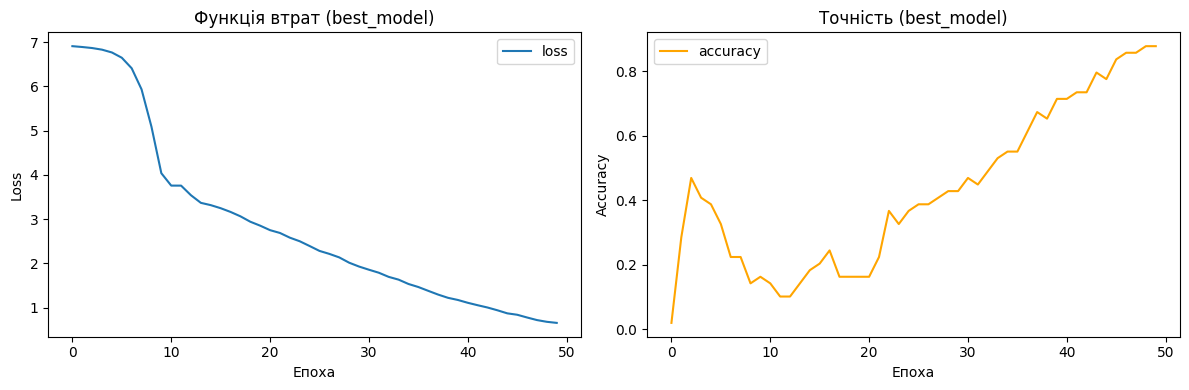

Модель            Loss    Accuracy
model           1.4649      0.5918
best_model      0.6586      0.8776
model:      Думи мої думи лихо лихо лихо на на на поливали поливали рядами не не папері в в чом як чом не не не
best_model: Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(best_history.history['loss'], label='loss')
axes[0].set_title('Функція втрат (best_model)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(best_history.history['accuracy'], label='accuracy', color='orange')
axes[1].set_title('Точність (best_model)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"{'Модель':<12}{'Loss':>10}{'Accuracy':>12}")
print(f"{'model':<12}{history.history['loss'][-1]:>10.4f}{history.history['accuracy'][-1]:>12.4f}")
print(f"{'best_model':<12}{best_history.history['loss'][-1]:>10.4f}{best_history.history['accuracy'][-1]:>12.4f}")


def buildPhrase(texts, str_len=20, model=model):
    data = tokenizer.texts_to_sequences([texts])[0]

    if len(data) < inp_words:
        raise ValueError(
            f"Потрібно щонайменше {inp_words} слова, відомих токенізатору "
            f"(знайдено {len(data)})."
        )

    res = texts
    for _ in range(str_len):
        x = np.array(data[-inp_words:]).reshape(1, inp_words)
        index = np.argmax(model.predict(x, verbose=0))
        data.append(index)
        res += " " + tokenizer.index_word.get(index, '')
    return res


print("model:     ", buildPhrase("Думи мої думи", 20, model))
print("best_model:", buildPhrase("Думи мої думи", 20, best_model))

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

Перший шар перетворює індекси слів на щільні векторні програми, інші два опрацьовують послідовність із трьох слів і враховують їхній порядок. останній шар dropout випадково вимикає частину нейронів щоб зменшити перенавчання. loss маємо 1.46 а accuracy 0.59. Після підбору параметрів вони покращилися до 0/65 та 0.87 відповідно.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.